# Regresión Logística + GPD (Horaria)

## Librerías, carpetas y constantes

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import metrics

import sys
from pathlib import Path

sys.path.append("..")
from src.model_hourly import (
    load_data,
    group_data_by_station,
    feature_engineering,
    split_data,
    build_logit_station_data,
    fit_logit_all_stations,
    build_exceedance_data,
    augment_exceedance_data,
    fit_cov_gpd_all_stations,
    summary,
    prepare_test_data,
    two_part_prob
)

In [ ]:
DATA = Path("..") / "data" / "procesados"
FIGURAS = Path("..") / "resultados" / "figuras" / "logreg_gpd"
COMPARACIONES = Path("..") / "resultados" / "tablas"

In [2]:
U = 63.0
R = 4
C = 90.0
VARIABLE = "O3"

## Cargar datos

In [ ]:
data = load_data("datos_corregidos.csv")
data2 = load_data("datos_no_imputados.csv")
station_data, STATIONS = group_data_by_station(data)    # Datos de entrenamiento
station_data2, STATIONS = group_data_by_station(data2)  # Datos de prueba
station_data = feature_engineering(station_data, STATIONS)
station_data2 = feature_engineering(station_data2, STATIONS)
station_train_data, _ = split_data(station_data, STATIONS)
_, station_test_data = split_data(station_data2, STATIONS, split="2026-01-01 00:00:00")

In [4]:
station_data2["CE"].tail()

,O3,PRS,RAINF,RH,SR,TOUT,WSR,WDR,wind_u,wind_v,hour_sin,hour_cos,month_sin,month_cos
Fecha y hora,,,,,,,,,,,,,,
2026-07-31 19:00:00,40.0,709.5,0.0,26.0,0.057,35.73,13.4,122.0,-13.056559,-3.014344,-0.965926,0.258819,-0.5,-0.866025
2026-07-31 20:00:00,40.0,709.6,0.0,25.0,0.007,34.88,13.3,105.0,-11.518138,-6.650000,-0.866025,0.500000,-0.5,-0.866025
2026-07-31 21:00:00,23.0,709.9,0.0,44.0,0.000,32.08,17.7,75.0,-8.850000,-15.328650,-0.707107,0.707107,-0.5,-0.866025
2026-07-31 22:00:00,21.0,710.3,0.0,48.0,0.000,30.66,15.6,74.0,-7.563030,-13.644067,-0.500000,0.866025,-0.5,-0.866025
2026-07-31 23:00:00,20.0,710.6,0.0,52.0,0.000,29.43,14.0,63.0,-4.326238,-13.314791,-0.258819,0.965926,-0.5,-0.866025


## Parte 1: Regresión Logística

In [22]:
logit_station_data = build_logit_station_data(station_train_data, STATIONS)
persistence_feats = ["x_t", "exc_t", "x_lag1", "x_lag24", "max24", "n_exc7"]
meteorological_feats = ["WSR", "TOUT", "RH", "wind_u", "wind_v"]
time_feats = ["hour_sin", "hour_cos"]
logit_feats = {
    "CE": persistence_feats + meteorological_feats + time_feats,
    "NE": persistence_feats + meteorological_feats + time_feats,
    "NE2": persistence_feats + time_feats,
    "NE3": persistence_feats + meteorological_feats + time_feats,
    "NO": persistence_feats + meteorological_feats + time_feats,
    "NO2": persistence_feats + meteorological_feats + time_feats,
    "NO3": persistence_feats + time_feats,
    "NTE": persistence_feats + meteorological_feats + time_feats,
    "NTE2": persistence_feats + meteorological_feats + time_feats,
    "SE": persistence_feats + meteorological_feats + time_feats,
    "SE2": persistence_feats + meteorological_feats + time_feats,
    "SE3": persistence_feats + meteorological_feats + time_feats,
    "SO": persistence_feats + time_feats,
    "SO2": persistence_feats + meteorological_feats + time_feats,
    "SUR": persistence_feats + meteorological_feats + time_feats,
}
logit_models = fit_logit_all_stations(logit_station_data, STATIONS, logit_feats)

## Parte 2: Modelo de la GPD

In [6]:
cols = ["WSR", "TOUT", "RH", "PRS", "SR", "hour_sin", "hour_cos", "month_sin", "month_cos", "wind_u", "wind_v"]
exceedance_station_data = build_exceedance_data(station_train_data, STATIONS, cols)
exceedance_station_data = augment_exceedance_data(exceedance_station_data, logit_models, logit_station_data, STATIONS)
met_covs = ["WSR", "TOUT", "RH", "wind_u", "wind_v"]
time_covs = ["hour_sin", "hour_cos"]
zeta_covs = ["zeta"]
covs = {
    "CE": met_covs+time_covs+zeta_covs,
    "NE": time_covs+zeta_covs,
    "NE2": zeta_covs,
    "NE3": zeta_covs,
    "NO": time_covs+zeta_covs,
    "NO2": zeta_covs,
    "NO3": zeta_covs,
    "NTE": zeta_covs,
    "NTE2": met_covs+time_covs+zeta_covs,
    "SE": met_covs,
    "SE2": time_covs+zeta_covs,
    "SE3": time_covs+zeta_covs,
    "SO": zeta_covs,
    "SO2": zeta_covs,
    "SUR": met_covs+time_covs+zeta_covs,
}
gpd_models = fit_cov_gpd_all_stations(exceedance_station_data, STATIONS, covs)

CE : 105 / 106
NE : 94 / 95
NE2 : 50 / 51
NE3 : 51 / 52
NO : 115 / 116
NO2 : 102 / 103
NO3 : 97 / 98
NTE : 113 / 114
NTE2 : 100 / 101
SE : 98 / 99
SE2 : 94 / 95
SE3 : 73 / 74
SO : 93 / 93
SO2 : 101 / 101
SUR : 93 / 93


In [7]:
for station in STATIONS:
    print("\n-----", station, "------")
    model = gpd_models[station]
    print(summary(model))


----- CE ------
               coef            se             z    p  exp(coef)
intercept  3.614055           NaN           NaN  NaN  37.116254
WSR       -0.750417  1.556284e-09 -4.821855e+08  0.0   0.472169
TOUT       0.233876  2.322605e-09  1.006955e+08  0.0   1.263488
RH        -0.049898  1.691859e-09 -2.949320e+07  0.0   0.951326
wind_u    -0.250185  1.340957e-09 -1.865718e+08  0.0   0.778657
wind_v    -0.800603  1.556284e-09 -5.144326e+08  0.0   0.449058
hour_sin  -0.147018  2.080931e-09 -7.064987e+07  0.0   0.863279
hour_cos   0.153799  1.691859e-09  9.090535e+07  0.0   1.166256
zeta       0.656738  2.490348e-09  2.637132e+08  0.0   1.928491
xi        -0.996116           NaN           NaN  NaN   0.369311

----- NE ------
               coef        se          z         p  exp(coef)
intercept  2.659562  0.134383  19.790843  0.000000  14.290032
hour_sin  -0.254396  0.135773  -1.873690  0.060973   0.775385
hour_cos   0.383108  0.166302   2.303696  0.021240   1.466837
zeta       1.0

/Users/ricardosalgadob/Desktop/Multivariados/MultiReto/notebooks/../src/model_hourly.py:263: RuntimeWarning: invalid value encountered in sqrt
  se = np.sqrt(np.diag(cov))
/Users/ricardosalgadob/Desktop/Multivariados/MultiReto/notebooks/../src/model_hourly.py:263: RuntimeWarning: invalid value encountered in sqrt
  se = np.sqrt(np.diag(cov))


## Parte 3: Evaluación

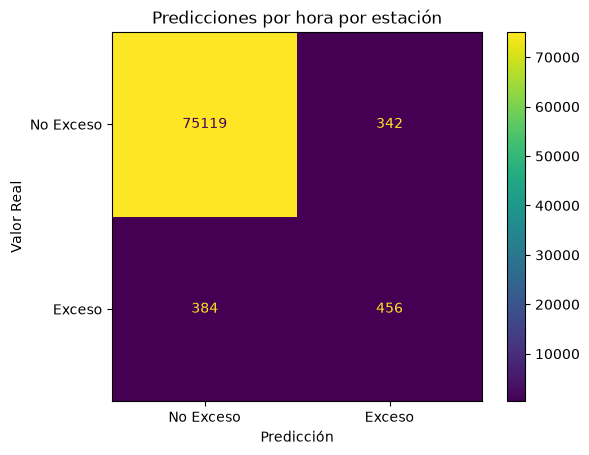

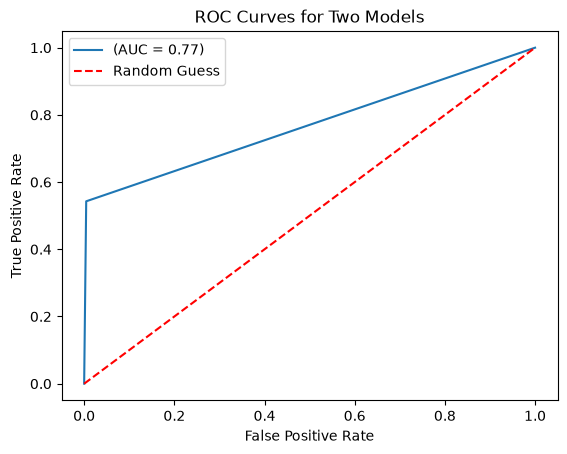

In [ ]:
preds_station = pd.DataFrame()
threshold = 0.44
for station in STATIONS:
    test = station_test_data[station]
    test = prepare_test_data(test)
    preds = pd.DataFrame(index=test.index)
    preds["x"] = test[VARIABLE]
    preds["real_exc"] = (preds["x"] >= C)
    lg_model = logit_models[station]
    gpd_model = gpd_models[station]
    p_c = two_part_prob(C, test, lg_model, gpd_model, U)
    preds["p"] = p_c
    # preds["p"] = preds["p"].shift(-6)
    preds["pred_exc"] = (preds["p"] >= threshold)
    preds["estacion"] = station
    preds_station = pd.concat([preds_station, preds])

confusion_matrix = metrics.confusion_matrix(preds_station["real_exc"], preds_station["pred_exc"])
cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix = confusion_matrix, display_labels = ["No Exceso", "Exceso"])
cm_display.plot()
plt.xlabel("Predicción")
plt.ylabel("Valor Real")
plt.title("Predicciones por hora por estación")
plt.savefig(FIGURAS / "confmat_hourly_by_hour_station.png")
plt.show()

fpr, tpr, _ = metrics.roc_curve(preds_station["real_exc"], preds_station["pred_exc"])
roc_auc = metrics.auc(fpr, tpr)
plt.plot(fpr, tpr, label=f'(AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'r--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves for Two Models')
plt.legend()
plt.show()

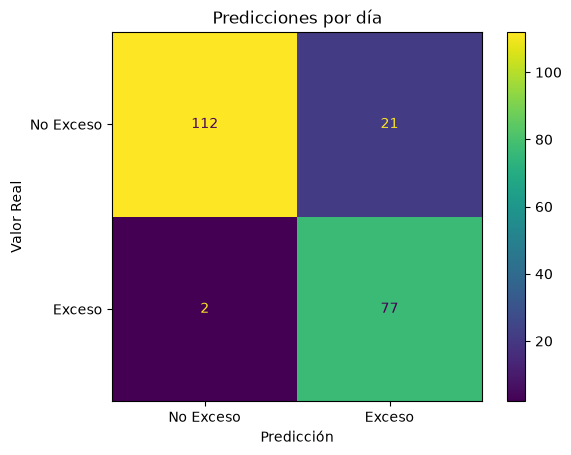

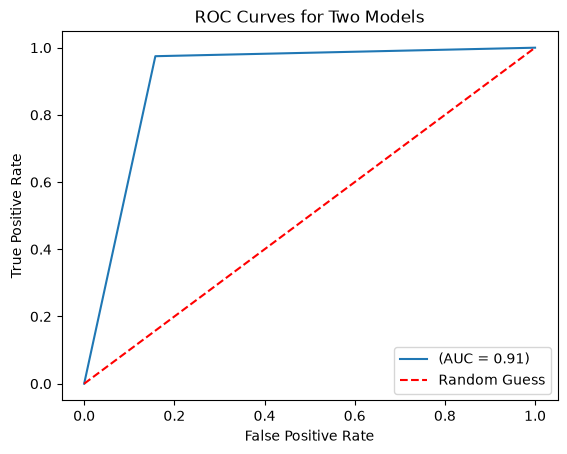

In [ ]:
t2 = 0.5
daily = preds_station[["x", "p"]].resample('D').max()
daily["real_exc"] = (daily["x"] >= C)
daily["pred_exc"] = (daily["p"] >= t2)
    
confusion_matrix = metrics.confusion_matrix(daily["real_exc"], daily["pred_exc"])
cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix = confusion_matrix, display_labels = ["No Exceso", "Exceso"])
cm_display.plot()
plt.xlabel("Predicción")
plt.ylabel("Valor Real")
plt.title("Predicciones por día")
plt.savefig(FIGURAS / "confmat_hourly_by_day.png")
plt.show()

fpr, tpr, _ = metrics.roc_curve(daily["real_exc"], daily["pred_exc"])
roc_auc = metrics.auc(fpr, tpr)
plt.plot(fpr, tpr, label=f'(AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'r--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves for Two Models')
plt.legend()
plt.show()

## Parte 4: Validación

In [10]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from scipy.stats import expon

In [11]:
def validate_logit(res, train, feats, mu, sd, make_plots=False):
    """
    Carries out statistical validations for a fitted statsmodels Logit result:
    1. Linearity in Log-Odds (Box-Tidwell)
    2. Multicollinearity (VIF)
    3. Influential Outliers (Cook's Distance & Studentized/Pearson Residuals)
    4. Independence of Errors (Durbin-Watson & Residuals vs Index plot)
    """
    results = {}
    
    # Standardize features as done in fit_logit
    Z_df = (train[feats] - mu) / sd
    Z_with_const = sm.add_constant(Z_df)
    
    # -------------------------------------------------------------------------
    # 1. Linearity in Log-Odds (Box-Tidwell Test)
    # -------------------------------------------------------------------------
    # Box-Tidwell tests interaction terms: X * ln(X). 
    # Since Z can be negative/zero, shift feature values strictly above zero: X_pos = X - min(X) + 1
    bt_data = Z_df.copy()
    bt_terms = []
    
    for col in feats:
        x_shift = train[col] - train[col].min() + 1.0
        x_ln_x = x_shift * np.log(x_shift)
        bt_term_name = f"{col}_x_ln"
        bt_data[bt_term_name] = x_ln_x
        bt_terms.append(bt_term_name)
        
    bt_design = sm.add_constant(bt_data)
    if train["y"].shape[0] > 50:
        bt_model = sm.Logit(train["y"], bt_design).fit(disp=0)
    else:
        bt_model = sm.Logit(train["y"], bt_design).fit_regularized(method="l1", disp=0)
        
    
    # Extract p-values for interaction terms (p < 0.05 indicates non-linearity)
    bt_pvalues = bt_model.pvalues[bt_terms]
    results['box_tidwell_pvalues'] = bt_pvalues
    
    # -------------------------------------------------------------------------
    # 2. Multicollinearity (Variance Inflation Factor - VIF)
    # -------------------------------------------------------------------------
    # VIF is calculated on the design matrix (including constant)
    vif_df = pd.DataFrame({
        'Feature': Z_with_const.columns,
        'VIF': [variance_inflation_factor(Z_with_const.values, i) 
                for i in range(Z_with_const.shape[1])]
    })
    results['vif'] = vif_df
    
    # -------------------------------------------------------------------------
    # 3. Influential Outliers (Cook's Distance & Studentized Residuals)
    # -------------------------------------------------------------------------
    influence = res.get_influence()
    cooks_d = influence.cooks_distance[0]
    
    # Person / Studentized Residuals
    residuals = res.resid_pearson
    
    n = len(train)
    cooks_threshold = 4 / n
    cook_idx = np.where(cooks_d > cooks_threshold)[0]
    pearson_idx = np.where(np.abs(residuals) > 3)[0]
    outliers_idx = np.where((cooks_d > cooks_threshold) | (np.abs(residuals) > 3))[0]
    
    results['cooks_distance'] = cooks_d
    results['residuals'] = residuals
    results['flagged_outliers_indices'] = train.index[outliers_idx].tolist()
    results['flagged_cook_indices'] = train.index[cook_idx].tolist()
    results['flagged_pearson_indices'] = train.index[pearson_idx].tolist()
    
    # -------------------------------------------------------------------------
    # 4. Independence of Errors (Durbin-Watson & Residual Plot)
    # -------------------------------------------------------------------------
    dw_stat = durbin_watson(residuals)
    results['durbin_watson'] = dw_stat

    # -------------------------------------------------------------------------
    # Visual Diagnostics
    # -------------------------------------------------------------------------
    if make_plots:
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        
        # Plot A: Cook's Distance
        axes[0].stem(range(n), cooks_d, markerfmt=" ", basefmt="k-")
        axes[0].axhline(y=cooks_threshold, color='r', linestyle='--', label=f'Threshold (4/n = {cooks_threshold:.4f})')
        axes[0].set_title("Cook's Distance")
        axes[0].set_xlabel("Observation Index")
        axes[0].set_ylabel("Cook's D")
        axes[0].legend()
        
        # Plot B: Residuals vs Index (Error Independence)
        axes[1].scatter(train.index, residuals, alpha=0.6, edgecolors='k', s=20)
        axes[1].axhline(y=0, color='r', linestyle='--')
        axes[1].axhline(y=3, color='g', linestyle=':', label='±3 Std Dev Bounds')
        axes[1].axhline(y=-3, color='g', linestyle=':')
        axes[1].set_title(f"Pearson Residuals vs Index (DW Stat: {dw_stat:.2f})")
        axes[1].set_xlabel("Train Index")
        axes[1].set_ylabel("Pearson Residuals")
        axes[1].legend()
        
        plt.tight_layout()
        plt.show()
    
    return results


def validate_all_logit_models(station_data, logit_models, station_names):
    validations = {}
    for station in station_names:
        train = station_data[station]
        res, mu, sd, feats = logit_models[station]
        validation = validate_logit(res, train, feats, mu, sd, station=="SUR")
        validations[station] = validation
    return validations


def residuals(m):
    beta, xi = m["params"][:-1], m["params"][-1]
    sigma = np.exp(m["Z"] @ beta)
    return np.log1p(xi * m["y"] / sigma) / xi

### Regresión Logística

/Users/ricardosalgadob/Desktop/Multivariados/MultiReto/.venv/lib/python3.12/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


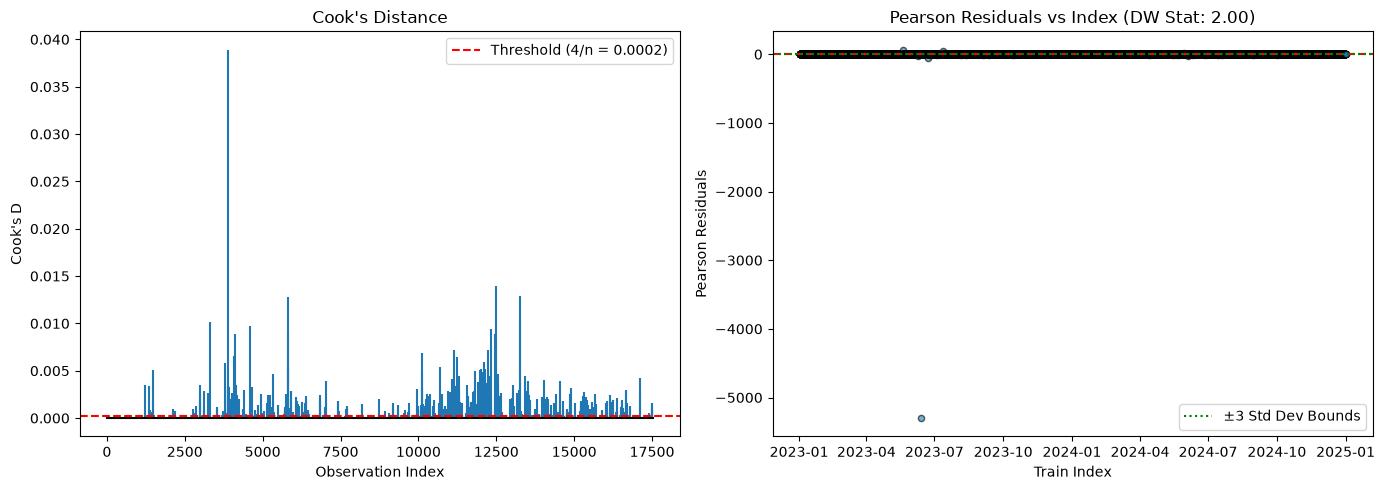

In [12]:
logit_validations = validate_all_logit_models(logit_station_data, logit_models, STATIONS)

In [13]:
print("--- Box-Tidwell Linearity Test (p < 0.05 implies non-linearity) ---")
print(logit_validations["SUR"]['box_tidwell_pvalues'].round(3))

--- Box-Tidwell Linearity Test (p < 0.05 implies non-linearity) ---
x_t_x_ln         0.000
exc_t_x_ln         NaN
x_lag1_x_ln      0.001
x_lag24_x_ln     0.001
max24_x_ln       0.207
n_exc7_x_ln      0.295
WSR_x_ln         0.701
TOUT_x_ln        0.054
RH_x_ln          0.087
wind_u_x_ln      0.682
wind_v_x_ln      0.446
hour_sin_x_ln    0.179
hour_cos_x_ln    0.125
dtype: float64


In [14]:
print("\n--- Variance Inflation Factors (VIF > 5-10 indicates high multicollinearity) ---")
print(logit_validations["SUR"]['vif'].round(3))


--- Variance Inflation Factors (VIF > 5-10 indicates high multicollinearity) ---
     Feature     VIF
0      const   1.000
1        x_t  10.673
2      exc_t   2.220
3     x_lag1   9.986
4    x_lag24   2.604
5      max24   1.863
6     n_exc7   2.306
7        WSR   2.816
8       TOUT   1.861
9         RH   1.811
10    wind_u   2.643
11    wind_v   1.472
12  hour_sin   2.146
13  hour_cos   1.491


In [15]:
print(f"\n--- Durbin-Watson Statistic: {logit_validations["SUR"]['durbin_watson']:.4f} ---")
print("(Values near 2.0 indicate independent errors; < 1.5 suggests positive autocorrelation)")


--- Durbin-Watson Statistic: 2.0000 ---
(Values near 2.0 indicate independent errors; < 1.5 suggests positive autocorrelation)


In [16]:
print(f"\nFlagged Outlier Indices: {len(logit_validations["SUR"]['flagged_outliers_indices'])} rows found.")
print(f"Flagged Outlier Indices (Cook): {len(logit_validations["SUR"]['flagged_cook_indices'])} rows found.")
print(f"Flagged Outlier Indices (Pearson): {len(logit_validations["SUR"]['flagged_pearson_indices'])} rows found.")


Flagged Outlier Indices: 681 rows found.
Flagged Outlier Indices (Cook): 681 rows found.
Flagged Outlier Indices (Pearson): 64 rows found.


### GPD

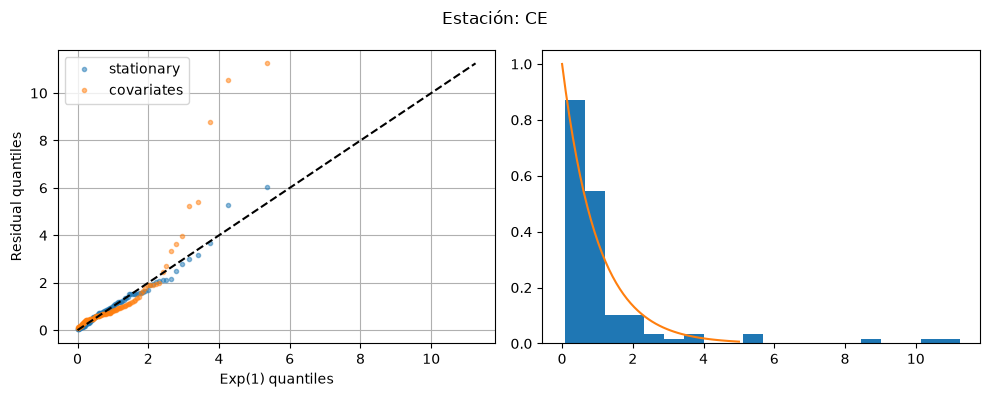

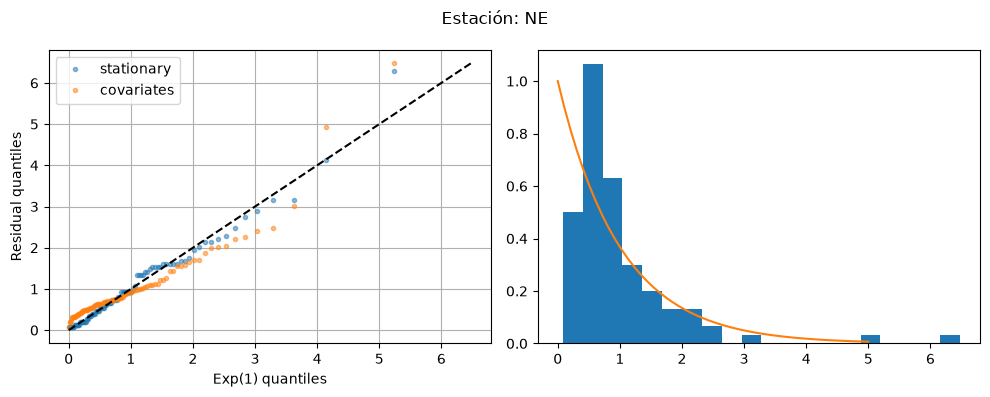

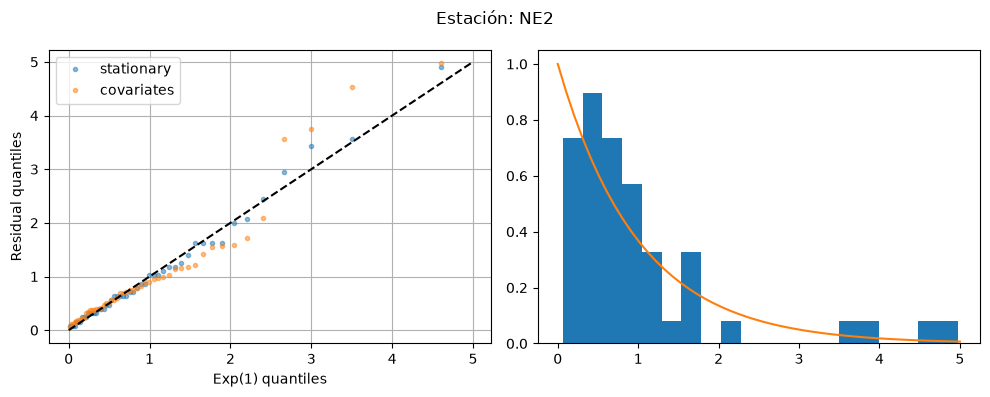

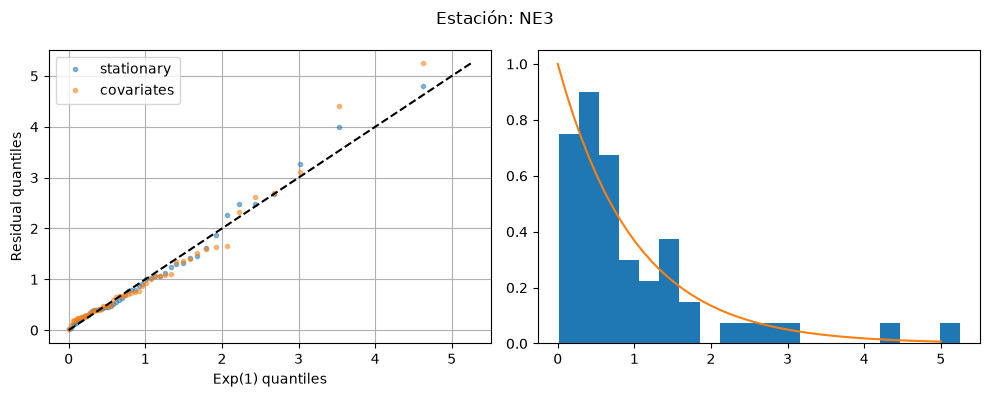

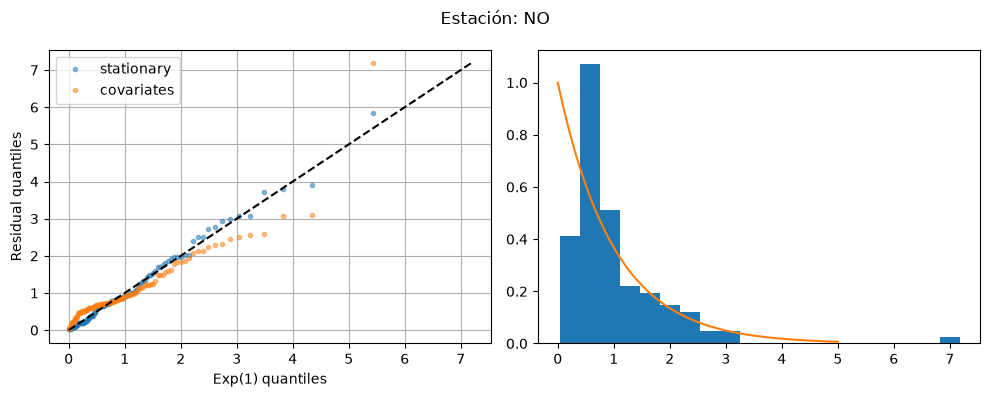

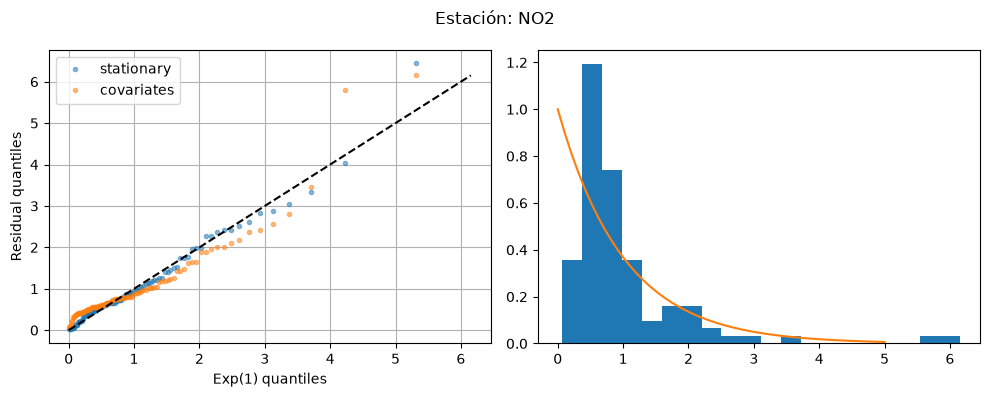

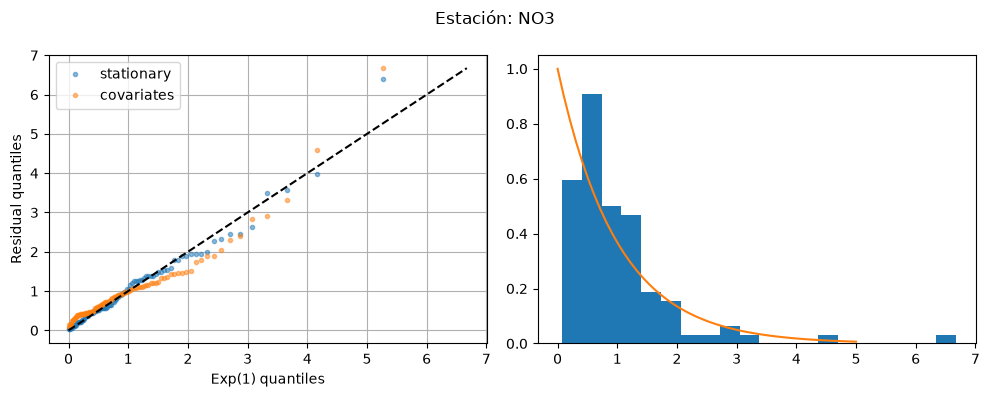

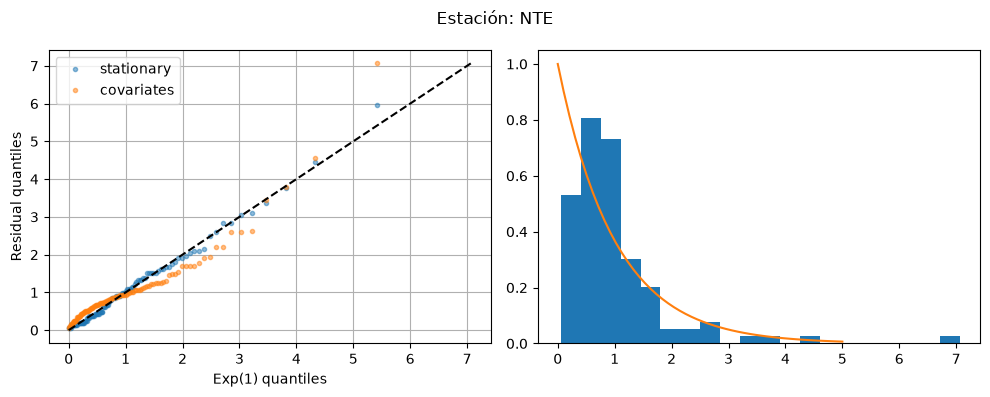

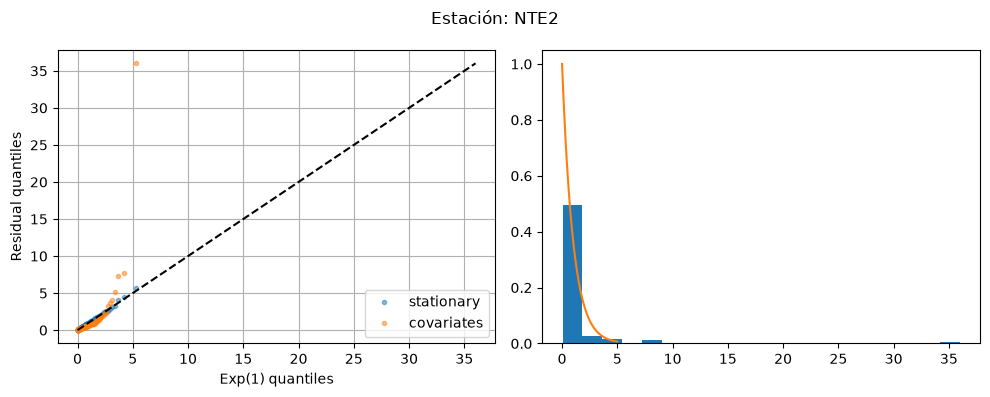

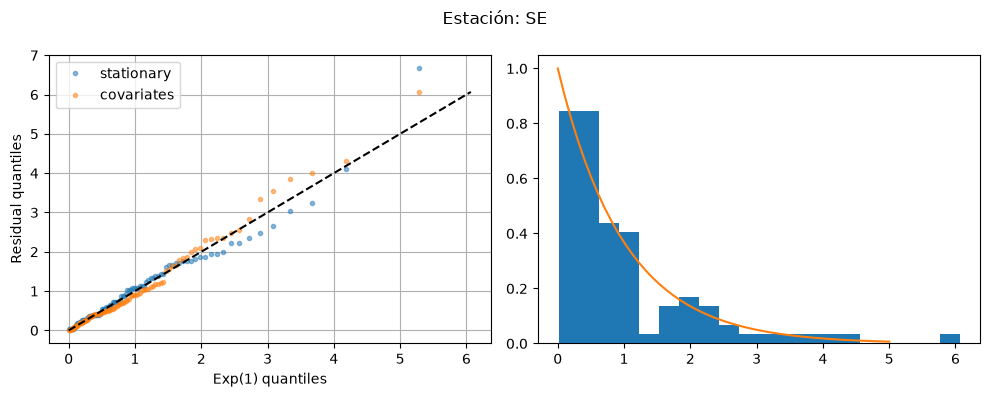

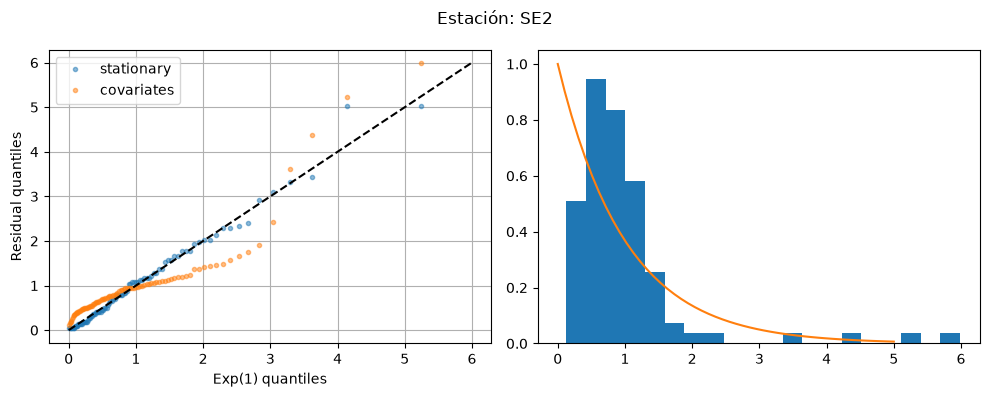

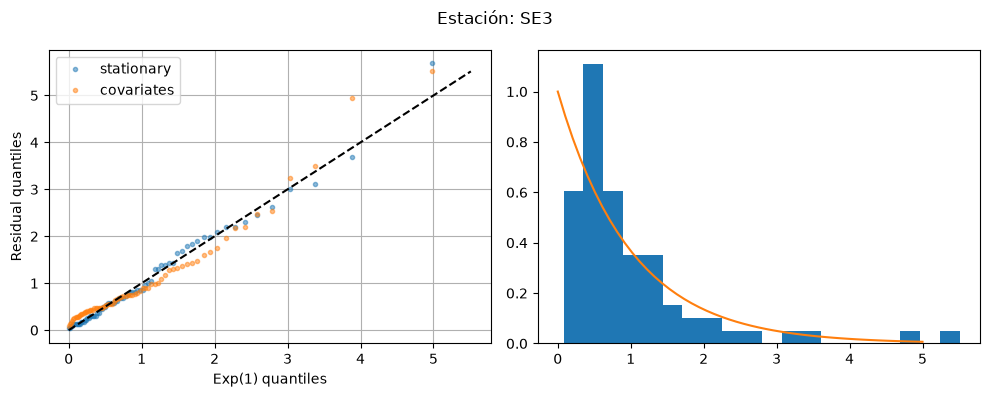

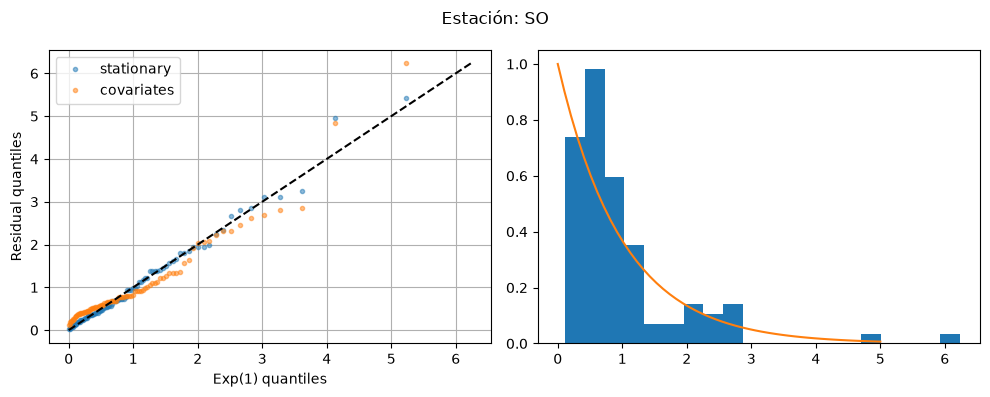

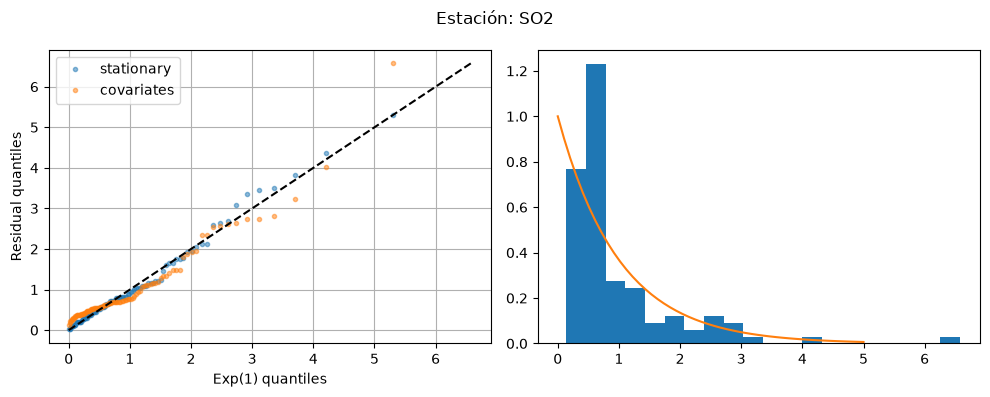

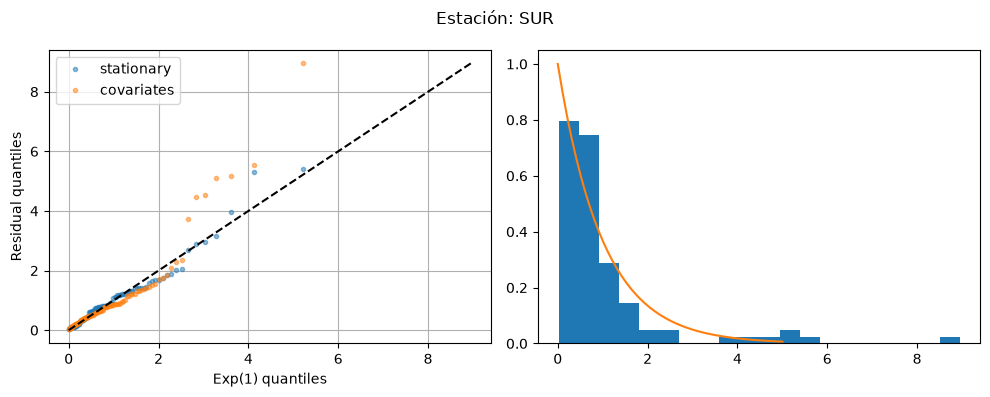

In [17]:
gpd_stat_models = fit_cov_gpd_all_stations(exceedance_station_data, STATIONS, [])

for j, station in enumerate(STATIONS):
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    m0 = gpd_stat_models[station]
    m1 = gpd_models[station]
    for m, lab in [(m0, "stationary"), (m1, "covariates")]:
        e = np.sort(residuals(m))
        q = expon.ppf((np.arange(1, len(e) + 1) - 0.5) / len(e))
        ax[0].plot(q, e, "o", ms=3, label=lab, alpha=0.5)
    lim = [0, max(q.max(), e.max())]
    ax[0].plot(lim, lim, "k--"); ax[0].set_xlabel("Exp(1) quantiles")
    ax[0].set_ylabel("Residual quantiles"); ax[0].legend()
    ax[1].hist(residuals(m1), bins=20, density=True)
    ax[1].plot(np.linspace(0, 5), expon.pdf(np.linspace(0, 5)))
    ax[0].grid()
    fig.suptitle(f"Estación: {station}")
    plt.tight_layout()
    plt.show()

## Parte 5: Comparación de modelos

In [18]:
from scipy.stats import chi2

In [19]:
LOGREG_MODEL_NAMES = (
    "( Persistence )",
    "( Persistence + Meteorological )",
    "( Persistence + Time )",
    "( Persistence + Meteorological + Time )",
)

GPD_MODEL_NAMES = (
    "( Stationary )",
    "( Meteorological )",
    "( Meteorological + Zeta )",
    "( Time )",
    "( Time + Zeta )",
    "( Meteorological + Time )",
    "( Meteorological + Time + Zeta )",
    "( Zeta )",
)

In [20]:
def lr_test_gpd(m_small, m_big):
    lr_stat = 2 * (m_small["nll"] - m_big["nll"])
    df = m_big["k"] - m_small["k"]
    p_value = 1 - chi2.cdf(lr_stat, df)
    return lr_stat, df, p_value


def lr_test_logreg(restricted_res, full_res):
    """
    Performs a Likelihood Ratio Test comparing two nested statsmodels Logit results.
    """
    # Likelihood Ratio Statistic
    lr_stat = 2 * (full_res.llf - restricted_res.llf)
    
    # Degrees of freedom difference
    df = full_res.df_model - restricted_res.df_model
    
    # p-value from Chi-Squared distribution
    p_value = chi2.sf(lr_stat, df)
    
    return lr_stat, df, p_value


def compare_logreg_to_null(models):
    null_comparisons = {
        "Model Name": [],
        "LR-test Statistic": [],
        "P-value": [],
        "Degrees of Freedom": [],
        "AIC": [],
    }
    for model, name in zip(models, LOGREG_MODEL_NAMES):
        null_comparisons["Model Name"].append(name)
        null_comparisons["LR-test Statistic"].append(model[0].llr)
        null_comparisons["P-value"].append(model[0].llr_pvalue)
        null_comparisons["Degrees of Freedom"].append(model[0].df_model)
        null_comparisons["AIC"].append(model[0].aic)
    return pd.DataFrame(null_comparisons)


def compare_logregs(models):
    comparisons = ((0, 1), (0, 2), (1, 3), (2, 3), (0, 3))
    comparisons_d = {
        "Comparison": [],
        "LR-test Statistic": [],
        "P-value": [],
        "Degrees of Freedom": [],
        "AIC_small": [],
        "AIC_big": [],
    }
    for small, big in comparisons:
        model_small, small_name = models[small], LOGREG_MODEL_NAMES[small]
        model_big, big_name = models[big], LOGREG_MODEL_NAMES[big]
        lr_stat, df, p_value = lr_test_logreg(model_small[0], model_big[0])
        comparisons_d["Comparison"].append(f"{small_name} vs {big_name}")
        comparisons_d["LR-test Statistic"].append(lr_stat)
        comparisons_d["P-value"].append(p_value)
        comparisons_d["Degrees of Freedom"].append(df)
        comparisons_d["AIC_small"].append(model_small[0].aic)
        comparisons_d["AIC_big"].append(model_big[0].aic)
    return pd.DataFrame(comparisons_d)


def compare_logreg_all_stations(
    model_family_1,
    model_family_2,
    model_family_3,
    model_family_4,
    station_names
):
    null_comparisons = pd.DataFrame({
        "Station": [],
        "Model Name": [],
        "LR-test Statistic": [],
        "P-value": [],
        "Degrees of Freedom": [],
        "AIC": [],
    })
    comparisons = pd.DataFrame({
        "Station": [],
        "Comparison": [],
        "LR-test Statistic": [],
        "P-value": [],
        "Degrees of Freedom": [],
        "AIC_small": [],
        "AIC_big": [],
    })
    for station in station_names:
        models = [
            model_family_1[station],
            model_family_2[station],
            model_family_3[station],
            model_family_4[station]
        ]
        
        # Null comparisons
        null_comp = compare_logreg_to_null(models)
        null_comp["Station"] = station
        null_comparisons = pd.concat([null_comparisons, null_comp])
        
        # Comparisons against one another
        comp = compare_logregs(models)
        comp["Station"] = station
        comparisons = pd.concat([comparisons, comp])
        
    return null_comparisons, comparisons


def compare_gpd(models):
    comparisons = (
        (0, 1), 
        (0, 2), (1, 2), (7, 2),
        (0, 3), 
        (0, 4), (3, 4), (7, 4),
        (0, 5), (1, 5), (3, 5), 
        (0, 6), (1, 6), (2, 6), (3, 6), (4, 6), (5, 6), (7, 6),
        (0, 7)
    )
    comparisons_d = {
            "Comparison": [],
            "LR-test Statistic": [],
            "P-value": [],
            "Degrees of Freedom": [],
            "AIC_small": [],
            "AIC_big": [],
        }
    for small, big in comparisons:
        model_small, small_name = models[small], GPD_MODEL_NAMES[small]
        model_big, big_name = models[big], GPD_MODEL_NAMES[big]
        lr_stat, df, p_value = lr_test_gpd(model_small, model_big)
        comparisons_d["Comparison"].append(f"{small_name} vs {big_name}")
        comparisons_d["LR-test Statistic"].append(lr_stat)
        comparisons_d["P-value"].append(p_value)
        comparisons_d["Degrees of Freedom"].append(df)
        aic_small = 2 * model_small["nll"] + 2 * model_small["k"]
        aic_big = 2 * model_big["nll"] + 2 * model_big["k"]
        comparisons_d["AIC_small"].append(aic_small)
        comparisons_d["AIC_big"].append(aic_big)
    return pd.DataFrame(comparisons_d)


def compare_gpd_all_stations(
    model_family_1,
    model_family_2,
    model_family_3,
    model_family_4,
    model_family_5,
    model_family_6,
    model_family_7,
    model_family_8,
    station_names
):
    comparisons = pd.DataFrame({
        "Station": [],
        "Comparison": [],
        "LR-test Statistic": [],
        "P-value": [],
        "Degrees of Freedom": [],
        "AIC_small": [],
        "AIC_big": [],
    })
    for station in station_names:
        models = [
            model_family_1[station],
            model_family_2[station],
            model_family_3[station],
            model_family_4[station],
            model_family_5[station],
            model_family_6[station],
            model_family_7[station],
            model_family_8[station],
        ]

        comp = compare_gpd(models)
        comp["Station"] = station
        comparisons = pd.concat([comparisons, comp])
        
    return comparisons


### Regresión Logística

In [ ]:
logit_persistence_models = fit_logit_all_stations(
    logit_station_data, 
    STATIONS, 
    persistence_feats
)
logit_met_models = fit_logit_all_stations(
    logit_station_data, 
    STATIONS, 
    persistence_feats + meteorological_feats
)
logit_time_models = fit_logit_all_stations(
    logit_station_data, 
    STATIONS, 
    persistence_feats + time_feats
)
logit_met_time_models = fit_logit_all_stations(
    logit_station_data,
    STATIONS, 
    persistence_feats + meteorological_feats + time_feats
)

# Logistic regression comparisons
null_comp_logreg_df, comp_logreg_df = compare_logreg_all_stations(
    logit_persistence_models,
    logit_met_models,
    logit_time_models,
    logit_met_time_models,
    STATIONS
)
null_comp_logreg_df.to_csv(COMPARACIONES / 'null_logreg_hourly.csv', index=False)
comp_logreg_df.to_csv(COMPARACIONES / 'logreg_hourly.csv', index=False)

In [24]:
null_comp_logreg_df.head()

,Station,Model Name,LR-test Statistic,P-value,Degrees of Freedom,AIC
0,CE,( Persistence ),6057.884182,0.0,6.0,2580.491321
1,CE,( Persistence + Meteorological ),6170.802014,0.0,11.0,2477.573489
2,CE,( Persistence + Time ),6262.607973,0.0,8.0,2379.767530
3,CE,( Persistence + Meteorological + Time ),6352.922159,0.0,13.0,2299.453345
0,NE,( Persistence ),3425.792637,0.0,6.0,1702.315212


In [25]:
comp_logreg_df.head()

,Station,Comparison,LR-test Statistic,P-value,Degrees of Freedom,AIC_small,AIC_big
0,CE,( Persistence ) vs ( Persistence + Meteorologi...,112.917832,9.900412e-23,5.0,2580.491321,2477.573489
1,CE,( Persistence ) vs ( Persistence + Time ),204.723791,3.505853e-45,2.0,2580.491321,2379.767530
2,CE,( Persistence + Meteorological ) vs ( Persiste...,182.120144,2.838658e-40,2.0,2477.573489,2299.453345
3,CE,( Persistence + Time ) vs ( Persistence + Mete...,90.314186,5.771930e-18,5.0,2379.767530,2299.453345
4,CE,( Persistence ) vs ( Persistence + Meteorologi...,295.037977,6.937982e-60,7.0,2580.491321,2299.453345


### GPD

In [26]:
met_time_exceedance_data = augment_exceedance_data(exceedance_station_data, logit_met_time_models, logit_station_data, STATIONS)
stationary_covs = []
met_covs = ["WSR", "TOUT", "RH", "wind_u", "wind_v"]
time_covs = ["hour_sin", "hour_cos"]
zeta_covs = ["zeta"]
gpd_stationary_models = fit_cov_gpd_all_stations(met_time_exceedance_data, STATIONS, stationary_covs)
gpd_met_models = fit_cov_gpd_all_stations(met_time_exceedance_data, STATIONS, met_covs)
gpd_met_zeta_models = fit_cov_gpd_all_stations(met_time_exceedance_data, STATIONS, met_covs + zeta_covs)
gpd_time_models = fit_cov_gpd_all_stations(met_time_exceedance_data, STATIONS, time_covs)
gpd_time_zeta_models = fit_cov_gpd_all_stations(met_time_exceedance_data, STATIONS, time_covs + zeta_covs)
gpd_met_time_models = fit_cov_gpd_all_stations(met_time_exceedance_data, STATIONS, met_covs + time_covs)
gpd_met_time_zeta_models = fit_cov_gpd_all_stations(met_time_exceedance_data, STATIONS, met_covs + time_covs + zeta_covs)
gpd_zeta_models = fit_cov_gpd_all_stations(met_time_exceedance_data, STATIONS, zeta_covs)

CE : 105 / 105
NE : 94 / 94
NE2 : 50 / 50
NE3 : 51 / 51
NO : 115 / 115
NO2 : 102 / 102
NO3 : 97 / 97
NTE : 113 / 113
NTE2 : 100 / 100
SE : 98 / 98
SE2 : 94 / 94
SE3 : 73 / 73
SO : 93 / 93
SO2 : 101 / 101
SUR : 93 / 93


In [ ]:
comp_gpd_df = compare_gpd_all_stations(
    gpd_stationary_models,
    gpd_met_models,
    gpd_met_zeta_models,
    gpd_time_models,
    gpd_time_zeta_models,
    gpd_met_time_models,
    gpd_met_time_zeta_models,
    gpd_zeta_models,
    STATIONS
)
comp_gpd_df.to_csv(COMPARACIONES / 'gpd_hourly.csv', index=False)

In [28]:
comp_gpd_df.head()

,Station,Comparison,LR-test Statistic,P-value,Degrees of Freedom,AIC_small,AIC_big
0,CE,( Stationary ) vs ( Meteorological ),56.360849,6.848377e-11,5.0,878.792904,832.432055
1,CE,( Stationary ) vs ( Meteorological + Zeta ),93.421862,0.000000e+00,6.0,878.792904,797.371042
2,CE,( Meteorological ) vs ( Meteorological + Zeta ),37.061013,1.144901e-09,1.0,832.432055,797.371042
3,CE,( Zeta ) vs ( Meteorological + Zeta ),43.555419,2.851014e-08,5.0,830.926462,797.371042
4,CE,( Stationary ) vs ( Time ),2.067575,3.556573e-01,2.0,878.792904,880.725329
